Logistic reg -> predicts probability that an observation belongs to a particular class.

### Binomial

In [75]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [76]:
data = pd.read_csv("Student Depression Detection Dataset/Student_Depression_Dataset.csv")

In [77]:
data.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='str')

In [78]:
data.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [79]:
data.describe(include="str")

,Gender,Family_background,Relationship_status,Marital_status,Living_style,friend_circle,Health_condition,Home_division,Depression
count,4464,4464,4464,4464,4464,4464,4464,4464,4464
unique,2,3,3,3,2,2,4,8,2
top,Female,Middle class,Single,Unmarried,Bachelor,Yes,Normal,Dhaka,No
freq,2462,2642,2803,3619,2449,3215,1787,1527,3263


In [80]:
data["Age"].describe() # check for incorrect values

count    4464.000000
mean       22.619176
std         2.022980
min        17.000000
25%        21.000000
50%        23.000000
75%        24.000000
max        28.000000
Name: Age, dtype: float64

In [81]:
data["Gender"].value_counts() # check for inconsistent spellings, spaces, or unexpected values.

Gender
Female    2462
Male      2002
Name: count, dtype: int64

In [82]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB
None


In [83]:
data.duplicated().sum()

np.int64(0)

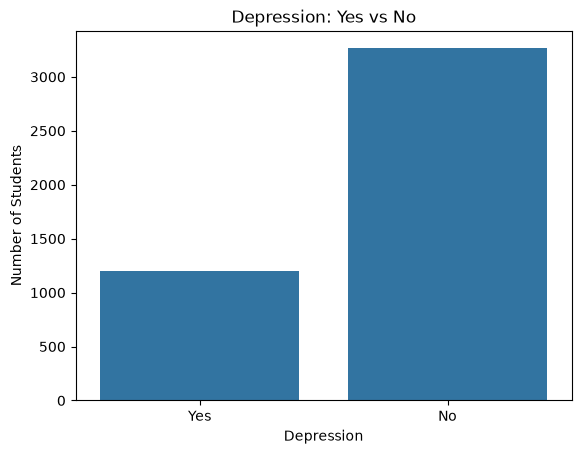

In [84]:
# check for class balance
sns.countplot(data=data, x="Depression")

plt.title("Depression: Yes vs No")
plt.xlabel("Depression")
plt.ylabel("Number of Students")

plt.show()

In [85]:
data["Depression"].value_counts()  # imbalanced class

Depression
No     3263
Yes    1201
Name: count, dtype: int64

In [86]:
# check if dataset is balanced
data["Depression"].value_counts(normalize=True) * 100

Depression
No     73.095878
Yes    26.904122
Name: proportion, dtype: float64

In case of null values, do replacement for only training dataset

In [87]:
data["Gender"].unique()
encoder = LabelEncoder()
data["Gender"] = encoder.fit_transform(data["Gender"])
print(data["Gender"].head())

0    0
1    1
2    1
3    1
4    0
Name: Gender, dtype: int64


In [88]:
data["Family_background"].unique()
data["Family_background"] = encoder.fit_transform(data["Family_background"])
print(data["Family_background"].head())

0    1
1    1
2    1
3    1
4    1
Name: Family_background, dtype: int64


In [89]:
data["Relationship_status"].unique()
data["Relationship_status"] = encoder.fit_transform(data["Relationship_status"])
print(data["Relationship_status"].head())

0    2
1    2
2    2
3    0
4    2
Name: Relationship_status, dtype: int64


In [90]:
data["Marital_status"].unique()
data["Marital_status"] = encoder.fit_transform(data["Marital_status"])
print(data["Marital_status"].head())

0    2
1    2
2    2
3    2
4    2
Name: Marital_status, dtype: int64


In [91]:
data["Living_style"].unique()

<StringArray>
['Bachelor', 'Family']
Length: 2, dtype: str

In [92]:
data["Home_division"].unique()

<StringArray>
['Chittagong',      'Dhaka',   'Rajshahi', 'Mymensingh',    'Barisal',
    'Rangpur',     'Khulna',     'Sylhet']
Length: 8, dtype: str

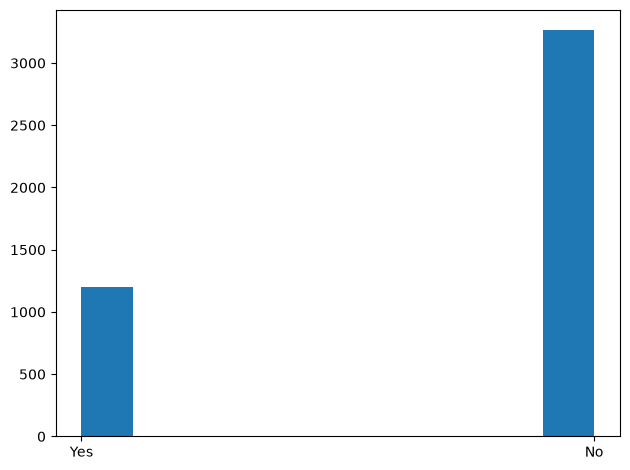

In [93]:
plt.hist(data["Depression"])
plt.tight_layout()
plt.show()

In [94]:
data.corr(numeric_only=True)

,Gender,Age,Family_background,Relationship_status,Marital_status,Current_semester,CGPA,Cost_without_study
Gender,1.000000,-0.137302,-0.261586,0.273621,0.182411,-0.066602,0.014017,-0.044720
Age,-0.137302,1.000000,0.118388,-0.067626,-0.286860,0.325304,-0.065085,-0.062625
Family_background,-0.261586,0.118388,1.000000,-0.194644,-0.127650,0.091831,-0.004150,0.595784
Relationship_status,0.273621,-0.067626,-0.194644,1.000000,0.285451,-0.050129,-0.039085,-0.120574
Marital_status,0.182411,-0.286860,-0.127650,0.285451,1.000000,-0.122949,-0.022183,-0.069829
Current_semester,-0.066602,0.325304,0.091831,-0.050129,-0.122949,1.000000,-0.007946,0.013762
CGPA,0.014017,-0.065085,-0.004150,-0.039085,-0.022183,-0.007946,1.000000,0.081900
Cost_without_study,-0.044720,-0.062625,0.595784,-0.120574,-0.069829,0.013762,0.081900,1.000000


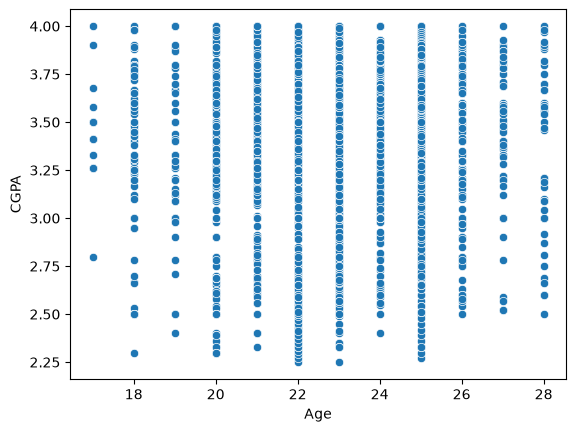

In [95]:
# Numerical vs numerical -> use correlation
sns.scatterplot(data=data, x="Age", y="CGPA")  # weak correlation
plt.show()

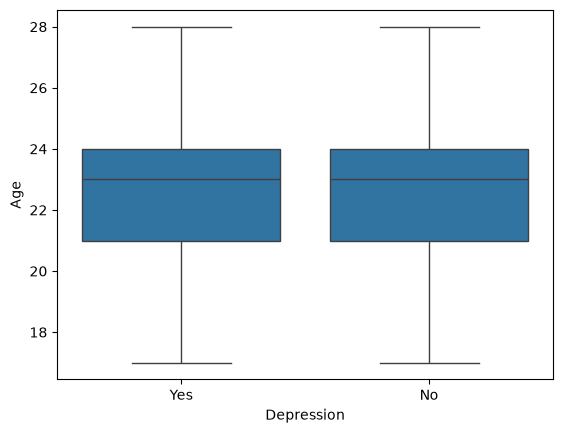

In [96]:
#Numerical feature vs categorical target
sns.boxplot(data=data, x="Depression", y="Age")
plt.show()
# shows does not mean what the age is depression ocurrs.

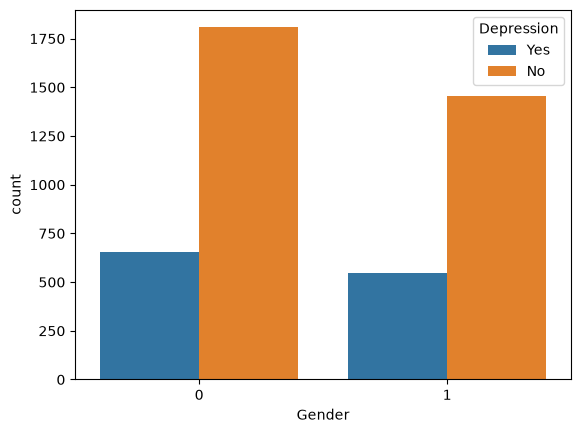

In [97]:
# Categorical feature vs categorical target
sns.countplot( data=data, x="Gender", hue="Depression")
plt.show()

Look how differet the results are in both different analysis.
each category is shown according to its own num of counts
as no of "FEMALE" category is high as compared to male. 
so, if we take it as if both category is same, then definitely depression rate will be higher in "MALE". 

In [98]:
# is used to compute a frequency table of two or more categorical factors. it counts how often pairs of values appear together in your dataset,
pd.crosstab(data["Gender"], data["Depression"], normalize="index") * 100

Depression,No,Yes
Gender,,
0,73.395613,26.604387
1,72.727273,27.272727


In [99]:
data["Gender"].value_counts()

Gender
0    2462
1    2002
Name: count, dtype: int64

In [100]:
pd.crosstab(data["Marital_status"], data["Depression"], normalize="index") * 100 # result is with respective of its own each category.
# just a freq table

Depression,No,Yes
Marital_status,,
0,88.000000,12.000000
1,80.000000,20.000000
2,69.881183,30.118817


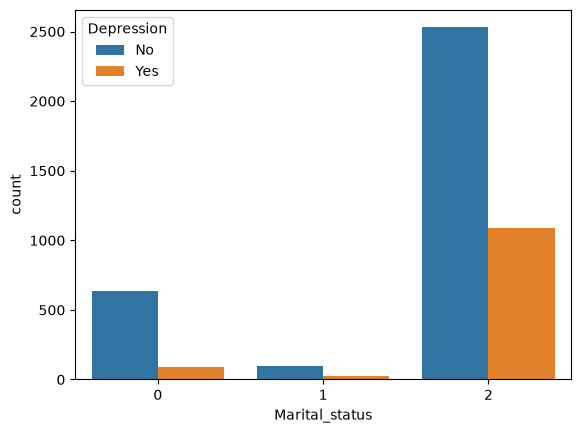

In [101]:
sns.countplot( data=data, x="Marital_status", hue="Depression")
plt.show()

#### Distribution of numerical features

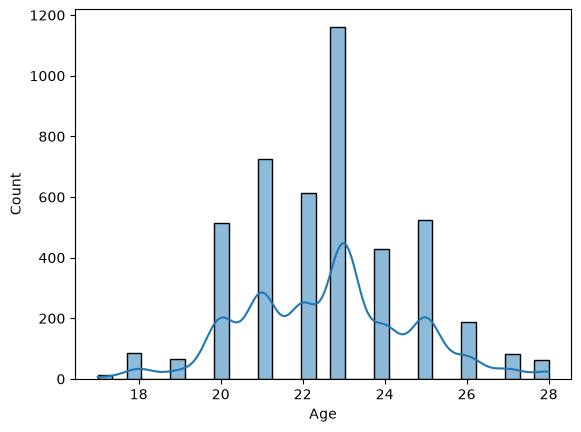

In [102]:
sns.histplot(data=data, x="Age", kde=True)
plt.show()

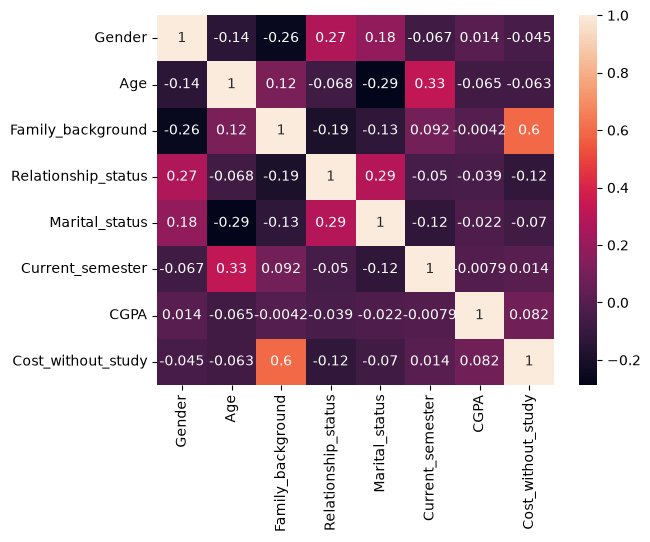

In [103]:
# check corelation to decide whcih features to include or not
numeric_data = data.select_dtypes(
    include="number"
)

sns.heatmap(
    numeric_data.corr(),
    annot=True
)

plt.show()

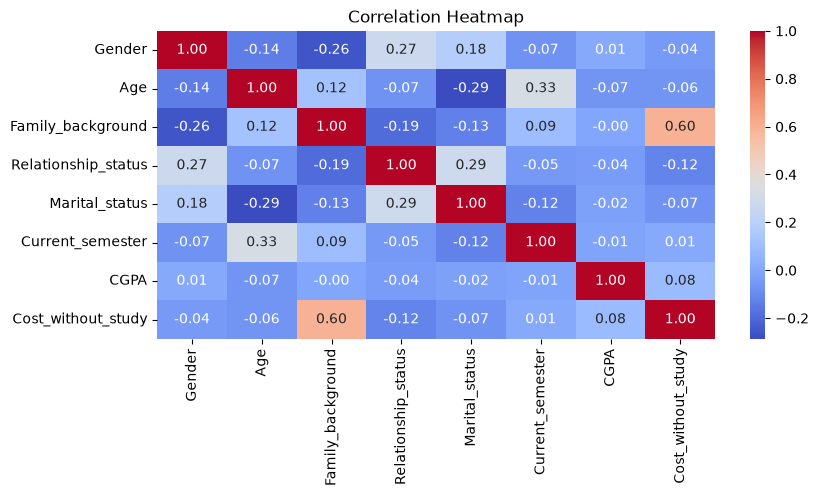

In [104]:
plt.figure(figsize=(9, 4))

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [105]:
x = data.drop("Depression", axis = 1)
y = data["Depression"]

to add cost without study column, we must normalize it first, due to difference in range, split for normalization

In [106]:
x = x.drop(["Living_style", "friend_circle", "Health_condition", "Home_division", "Cost_without_study"], axis = 1)

stratify helps maintain the class distributions across training and testing data, avoiding one class dominance over other. 

In [107]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 40, stratify=y)

In [108]:
model = LogisticRegression(class_weight = "balanced", max_iter = 1000)

In [109]:
model.fit(x_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [110]:
y_pred = model.predict(x_test)

In [122]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(results.head())

     Actual Predicted
634      No        No
117      No       Yes
205      No        No
4192     No       Yes
1260     No        No


In [112]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.83      0.51      0.63       653
         Yes       0.35      0.71      0.47       240

    accuracy                           0.56       893
   macro avg       0.59      0.61      0.55       893
weighted avg       0.70      0.56      0.59       893



In [120]:
coefficients = pd.DataFrame({
    "Feature": x.columns,
    "Coefficient": model.coef_[0]
})

print(coefficients.sort_values(
    by="Coefficient",
    ascending=False
))

               Feature  Coefficient
3  Relationship_status     1.237059
4       Marital_status     0.359955
5     Current_semester     0.000508
1                  Age    -0.017295
2    Family_background    -0.096568
0               Gender    -0.421178
6                 CGPA    -0.595826
